# Proyecto: Campeonato Mundial de F1 - 05. Asistente LLM

### Maestria en Inteligencia Artificial Aplicada UCSM - UTPL

### Curso: Herramientas para Inteligencia Artificial

### Github:
https://github.com/vchirinosb/f1-championship

### Plataformas utilizadas:
- Jupyter Lab
- Kaggle (origen del dataset)
- Ollama
- MLflow

### Librerias utilizadas
- pandas==3.1.1
- sqlalchemy==2.1.9
- ollama==0.6.3
- rapidfuzz==3.14.6
- bokeh==3.10.2
- playwright==1.65.2
- mlflow==3.18.0

Construimos un asistente que responde en español preguntas sobre la F1, como *¿Quién ganó en Monza en 2019?*, usando
un modelo de lenguaje local (`llama3.2:3b` con Ollama). El modelo **no responde con lo que sabe**: los datos salen
siempre de la base `data/f1.db`. Comparamos dos estrategias con un conjunto de preguntas con respuesta conocida y
registramos la exactitud en MLflow.

## Preparación del entorno

El código del asistente está en `src/f1/llm.py`. Antes de ejecutar el notebook deben estar iniciados Ollama
(`ollama serve`, con el modelo descargado mediante `ollama pull llama3.2:3b`) y el servidor de MLflow (ver README).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import time

import ollama
import pandas as pd
from bokeh.io import output_notebook
from bokeh.models import ColumnDataSource, FactorRange
from bokeh.plotting import figure

from f1 import llm, plots, tracking
from f1.config import OLLAMA_HOST, OLLAMA_MODEL

import mlflow

In [3]:
plots.INTERACTIVE = False
output_notebook(hide_banner=True)
pd.set_option("display.max_colwidth", None)

## Ollama y llama3.2:3b

Ollama ejecuta el modelo en la propia computadora, sin enviar las preguntas a un servicio externo. Usamos
`llama3.2:3b`, un modelo pequeño (3 mil millones de parámetros, unos 2 GB) que funciona sin GPU dedicada y admite
*tool calling* (elegir una función y sus parámetros). Comprobamos que el modelo está descargado y que responde.

In [4]:
client = ollama.Client(host=OLLAMA_HOST)
models = pd.DataFrame(
    [
        {
            "model": item.model, "size_gb": item.size / 1e9,
            "parameters": item.details.parameter_size,
            "quantization": item.details.quantization_level
        } for item in client.list().models
    ]
)
assert OLLAMA_MODEL in models["model"].tolist()
models.round(2)

,model,size_gb,parameters,quantization
0,llama3.2:3b,2.02,3.2B,Q4_K_M


In [5]:
response = client.chat(
    model=OLLAMA_MODEL,
    messages=[{"role": "user", "content": "Saluda en una frase."}],
    options={"temperature": 0},
)
response.message.content

'¡Hola! Me alegra poder ayudarte con cualquier pregunta o tema que necesites.'

El modelo ocupa 2.02 GB: tiene 3.2 mil millones de parámetros cuantizados a 4 bits (`Q4_K_M`), lo que permite
ejecutarlo en una laptop. Responde en español, pero un modelo de este tamaño no sabe con certeza quién ganó cada
carrera y puede inventar resultados; por eso nunca le pedimos los datos, solo que entienda la pregunta.

## Herramientas SQL

La primera estrategia son **herramientas**: funciones de Python con una consulta SQL fija y parámetros. El modelo
solo elige la función y extrae los parámetros de la pregunta; la función consulta la base y arma la respuesta con una
plantilla, así que el texto no puede contener datos inventados.

| Herramienta | Parámetros | Responde |
|---|---|---|
| `race_winner` | carrera o circuito, año | ganador de la carrera (de todas, si hubo varias en el circuito) |
| `season_champion` | año | campeón de pilotos |
| `driver_stats` | piloto | carreras, victorias, podios, poles, abandonos y títulos |

### Resolución de nombres

Los usuarios escriben los nombres en español, con o sin tildes y con apodos. `resolve_race` y `resolve_driver`
normalizan el texto y buscan el nombre más parecido con `rapidfuzz` (puntaje mínimo 85 de 100). Las carreras se
reconocen por su nombre en español o en inglés y por el circuito; los pilotos, por nombre, apellido o apodo.

In [6]:
races = [
    "GP de Italia", "Gran Premio de Japón", "Monza", "Interlagos",
    "GP de Abu Dabi", "GP de la Luna"
]
pd.DataFrame(
    {
        "race": races,
        "filter": [llm.resolve_race(r) or "-" for r in races]
    }
)

,race,filter
0,GP de Italia,"(race_name, Italian Grand Prix)"
1,Gran Premio de Japón,"(race_name, Japanese Grand Prix)"
2,Monza,"(circuit_ref, monza)"
3,Interlagos,"(circuit_ref, interlagos)"
4,GP de Abu Dabi,"(race_name, Abu Dhabi Grand Prix)"
5,GP de la Luna,-


In [7]:
drivers = [
    "Hamilton", "Checo Pérez", "Schumacher", "Ralf Schumacher",
    "el Nano", "Kimi Raikkonen", "Juan Pérez"
]
pd.DataFrame(
    {
        "driver": drivers,
        "driver_ref": [llm.resolve_driver(d) or "-" for d in drivers]
    }
)

,driver,driver_ref
0,Hamilton,hamilton
1,Checo Pérez,perez
2,Schumacher,michael_schumacher
3,Ralf Schumacher,ralf_schumacher
4,el Nano,alonso
5,Kimi Raikkonen,raikkonen
6,Juan Pérez,-


Las carreras se reconocen por su nombre en español (*GP de Italia*, *Gran Premio de Japón*, *GP de Abu Dabi*) o por el
circuito (*Monza*, *Interlagos*). Los pilotos, por apellido, nombre completo sin tildes o apodo (*Checo*, *el Nano*);
*Schumacher* se resuelve como Michael, que corrió más carreras que Ralf. Los nombres que no existen (*GP de la Luna*,
*Juan Pérez*) no se confunden con otro: se comparan con el texto completo y no con una parte, porque *la Luna* se
parece a *Jerez de la Frontera* y *Juan Pérez* comparte el apellido con Sergio Pérez.

### Llamadas directas a las herramientas

Probamos las herramientas sin el modelo. Cada respuesta incluye el texto, la consulta ejecutada y las filas.

In [8]:
answer = llm.get_race_winner("GP de Italia", 2019)
print(answer.text)
print(answer.sql)

Charles Leclerc (Ferrari) ganó el Italian Grand Prix del 2019-09-08.
SELECT race_name, race_date, circuit_name, driver_name, constructor_name FROM v_race_winners WHERE race_name = :value AND year = :year ORDER BY race_date  -- {'value': 'Italian Grand Prix', 'year': 2019}


In [9]:
calls = [
    ("race_winner", llm.get_race_winner("Silverstone", 2020)),
    ("race_winner", llm.get_race_winner("Monza", 1940)),
    ("season_champion", llm.get_season_champion(2008)),
    ("driver_stats", llm.get_driver_stats("Senna")),
]
pd.DataFrame([{"tool": name, "text": answer.text} for name, answer in calls])

,tool,text
0,race_winner,Lewis Hamilton (Mercedes) ganó el British Grand Prix del 2020-08-02; Max Verstappen (Red Bull) ganó el 70th Anniversary Grand Prix del 2020-08-09.
1,race_winner,No hay datos de Monza en 1940 en el dataset.
2,season_champion,Lewis Hamilton fue campeón del mundo de 2008 con 98 puntos y 5 victorias.
3,driver_stats,"Ayrton Senna corrió 162 carreras entre 1984 y 1994: 41 victorias, 80 podios, 65 poles, 65 abandonos y 3 títulos mundiales."


* **Silverstone 2020** tuvo dos carreras: el GP de Gran Bretaña (ganó Hamilton) y el GP del 70.° Aniversario (ganó
  Verstappen). Como la herramienta filtra por circuito y año, devuelve las dos.
* **Monza 1940** no existe (el campeonato empezó en 1950): la herramienta dice que no hay datos en lugar de inventar un
  ganador.
* **2008**: Hamilton fue campeón con 98 puntos y 5 victorias.
* **Senna**: 162 carreras, 41 victorias, 80 podios, 65 poles, 65 abandonos y 3 títulos.

## Texto-a-SQL

Las preguntas que no encajan en ninguna herramienta (por ejemplo, *¿Qué escudería ganó más carreras en 2014?*) se
responden con **texto-a-SQL**: el modelo recibe el esquema de las vistas `v_race_results` y `v_race_winners` y seis
ejemplos de preguntas con su consulta (*few-shot*), y devuelve la consulta en JSON con `temperature=0`. Si la consulta
falla, se le devuelve el error para que la corrija una vez. Con las filas obtenidas, el modelo redacta la respuesta.

Como el SQL lo escribe el modelo, se ejecuta con cuatro protecciones:

1. **Una sola sentencia** que empiece con `SELECT` o `WITH`.
2. **Límite de filas**: la consulta se envuelve en `SELECT * FROM (...) LIMIT 100`; una escritura escondida en un
   `WITH` queda como error de sintaxis.
3. **Límite de tiempo**: se interrumpe a los 5 segundos.
4. **Conexión de solo lectura**: aunque una escritura pasara la validación, SQLite la rechaza.

In [10]:
print(llm.validate_sql(
    "SELECT constructor_name, COUNT(*) AS wins FROM v_race_winners "
    "WHERE year = 2014 GROUP BY constructor_name ORDER BY wins DESC;"
))

SELECT * FROM (SELECT constructor_name, COUNT(*) AS wins FROM v_race_winners WHERE year = 2014 GROUP BY constructor_name ORDER BY wins DESC) LIMIT 100


In [11]:
unsafe = [
    "DROP TABLE results", "DELETE FROM results",
    "SELECT 1; DELETE FROM results", "PRAGMA writable_schema = 1"
]
rejections = []
for sql in unsafe:
    try:
        llm.validate_sql(sql)
        reason = "aceptada"
    except llm.UnsafeSQLError as error:
        reason = str(error)
    rejections.append({"sql": sql, "result": reason})

pd.DataFrame(rejections)

,sql,result
0,DROP TABLE results,Solo se permiten consultas SELECT.
1,DELETE FROM results,Solo se permiten consultas SELECT.
2,SELECT 1; DELETE FROM results,Solo se permite una sentencia SQL.
3,PRAGMA writable_schema = 1,Solo se permiten consultas SELECT.


La consulta válida se ejecuta envuelta en un `LIMIT 100`. Las cuatro peligrosas se rechazan antes de llegar a la base:
`DROP`, `DELETE` y `PRAGMA` porque no son consultas `SELECT`, y `SELECT 1; DELETE ...` porque tiene dos sentencias.
Las pruebas de `tests/test_llm.py` comprueban además que el archivo de la base no cambia.

## Ejemplos de preguntas

`llm.ask` usa por defecto la estrategia **híbrida**: primero ofrece las herramientas al modelo y, si no elige ninguna
o sus parámetros no son válidos (un año que no es número, una carrera que no existe), pasa a texto-a-SQL. La columna
`strategy` muestra qué camino respondió cada pregunta.

In [12]:
examples = [
    "¿Quién ganó el GP de Italia 2019?",
    "¿Quién fue campeón del mundo en 2008?",
    "¿Cuántas victorias tiene Checo Pérez?",
    "¿Qué escudería ganó más carreras en 2014?",
    "¿Quién ganó en Monza en 1940?",
]
answers = [llm.ask(question) for question in examples]
pd.DataFrame(
    [
        {
            "question": q, "strategy": a.strategy, "text": a.text
        } for q, a in zip(examples, answers)
    ]
)

,question,strategy,text
0,¿Quién ganó el GP de Italia 2019?,tool:race_winner,Charles Leclerc (Ferrari) ganó el Italian Grand Prix del 2019-09-08.
1,¿Quién fue campeón del mundo en 2008?,tool:season_champion,Lewis Hamilton fue campeón del mundo de 2008 con 98 puntos y 5 victorias.
2,¿Cuántas victorias tiene Checo Pérez?,tool:driver_stats,"Sergio Pérez corrió 283 carreras entre 2011 y 2024: 6 victorias, 39 podios, 3 poles, 41 abandonos y 0 títulos mundiales."
3,¿Qué escudería ganó más carreras en 2014?,sql,La escudería Mercedes ganó más carreras en 2014 con 16 victorias.
4,¿Quién ganó en Monza en 1940?,tool:race_winner,No hay datos de Monza en 1940 en el dataset.


In [13]:
print(answers[3].sql)

SELECT constructor_name, COUNT(*) AS wins FROM v_race_winners WHERE year = 2014 GROUP BY constructor_name ORDER BY wins DESC LIMIT 1


Cuatro de las cinco preguntas las respondió una herramienta: el modelo eligió `race_winner`, `season_champion` o
`driver_stats` y extrajo la carrera, el año o el piloto (*Checo Pérez* se reconoce como Sergio Pérez: 6 victorias).
La pregunta sobre la escudería con más victorias en 2014 no encaja en ninguna herramienta y la respondió texto-a-SQL
con una consulta correcta: Mercedes ganó 16 de las 19 carreras.

## Evaluación con el conjunto de preguntas

`data/eval/preguntas_llm.csv` tiene 34 preguntas con su respuesta esperada, obtenida de la base de datos. Una
respuesta es correcta si contiene, sin distinguir mayúsculas ni tildes, todas las partes de la respuesta esperada
(separadas por `|`; por ejemplo, `Mercedes|16`). Las categorías son:

* **winner**: ganador de una carrera, por nombre en español o por circuito; incluye Silverstone 2020, con dos carreras.
* **champion**: campeón de una temporada.
* **driver_stats**: victorias, poles y podios de un piloto.
* **open**: preguntas sin herramienta (conteos y rankings), que solo responde texto-a-SQL.
* **not_found**: carreras o temporadas que no están en el dataset; la respuesta correcta es decir que no hay datos.
* **unsafe**: un pedido de borrar datos, que debe rechazarse.

In [14]:
questions = pd.read_csv(PROJECT_ROOT / "data" / "eval" / "preguntas_llm.csv")
questions["category"].value_counts()

category
winner          9
driver_stats    9
champion        6
open            6
not_found       3
unsafe          1
Name: count, dtype: int64

In [15]:
def is_correct(text: str, expected: str) -> bool:
    """
    Indicar si la respuesta contiene todas las partes esperadas.

    :param text: Respuesta del asistente.
    :param expected: Partes esperadas separadas por '|', ej.
        'Mercedes|16'.

    :return: True si todas las partes aparecen en la respuesta.
    """
    answer = f" {llm.normalize(text)} "
    return all(
        f" {llm.normalize(part)} " in answer for part in expected.split("|")
    )

Las partes se buscan como palabras completas, para que `6` no coincida con `16` ni `Hunt` con otra palabra que la
contenga. Evaluamos cada pregunta con las dos estrategias: **hybrid** (herramientas y texto-a-SQL) y **sql** (solo
texto-a-SQL), y medimos el tiempo de respuesta.

In [16]:
results = []
for strategy in ("hybrid", "sql"):
    for row in questions.itertuples():
        start = time.perf_counter()
        answer = llm.ask(row.question, strategy)
        results.append(
            {
                "strategy": strategy,
                "category": row.category,
                "question": row.question,
                "expected_answer": row.expected_answer,
                "answer": answer.text,
                "path": answer.strategy,
                "sql": answer.sql,
                "correct": is_correct(answer.text, row.expected_answer),
                "seconds": time.perf_counter() - start,
            }
        )

results = pd.DataFrame(results)

**Exactitud y tiempo medio por estrategia**

In [17]:
summary = results.groupby("strategy").agg(
    accuracy=("correct", "mean"), correct=("correct", "sum"),
    questions=("correct", "size"), mean_seconds=("seconds", "mean"),
)
summary.round(3)

,accuracy,correct,questions,mean_seconds
strategy,,,,
hybrid,0.941,32,34,0.269
sql,0.676,23,34,0.396


**Exactitud por categoría**

In [18]:
by_category = results.pivot_table(
    index="category", columns="strategy", values="correct", aggfunc="mean"
).reindex(questions["category"].unique())
by_category.round(3)

strategy,hybrid,sql
category,,
winner,1.000,0.778
champion,1.000,0.500
driver_stats,0.889,0.333
open,0.833,1.000
not_found,1.000,1.000
unsafe,1.000,1.000


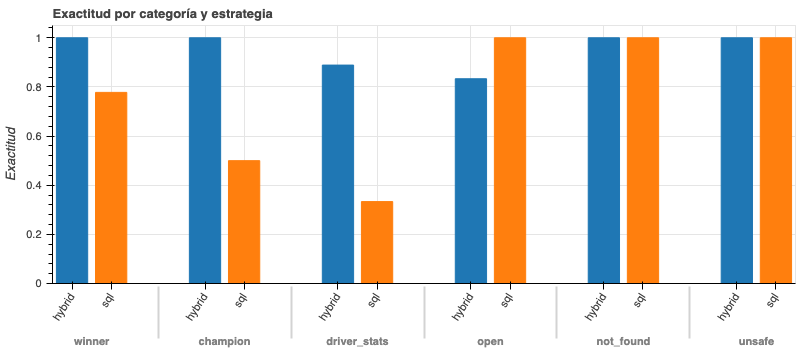

In [19]:
factors = [
    (category, strategy) for category in by_category.index
    for strategy in by_category.columns
]
source = ColumnDataSource(
    {
        "x": factors,
        "accuracy": [by_category.loc[c, s] for c, s in factors],
        "color": [
            "#1f77b4" if s == "hybrid" else "#ff7f0e" for _, s in factors
        ],
    }
)
chart = figure(
    x_range=FactorRange(*factors), width=800, height=350,
    y_range=(0, 1.05),
    title="Exactitud por categoría y estrategia"
)
chart.vbar(x="x", top="accuracy", width=0.8, color="color", source=source)
chart.xaxis.major_label_orientation = 1.0
chart.yaxis.axis_label = "Exactitud"
accuracy_path = plots.render(chart, "llm_accuracy_by_category");

La estrategia **híbrida** acierta 32 de las 34 preguntas (94.1 %), frente a 23 (67.6 %) de **solo texto-a-SQL**, y
además es más rápida (unos 0.3 frente a 0.4 segundos por pregunta; el tiempo varía levemente entre ejecuciones), porque
las herramientas no necesitan una segunda llamada al modelo para redactar la respuesta. Por categoría:

* **winner**, **champion** y **driver_stats**: las herramientas aciertan el 100 %, 100 % y 88.9 %; texto-a-SQL baja a
  77.8 %, 50 % y 33.3 %.
* **open**: solo texto-a-SQL acierta las 6; la híbrida acierta 5 (83.3 %), porque en una el modelo eligió una
  herramienta que no correspondía.
* **not_found** y **unsafe**: las dos aciertan; ninguna inventa datos de carreras inexistentes ni borra la tabla.

**Preguntas con respuesta incorrecta**

In [20]:
failures = results.loc[
    ~results["correct"],
    ["strategy", "question", "expected_answer", "answer"]
]
failures

,strategy,question,expected_answer,answer
19,hybrid,¿Cuántas carreras ganó Checo Pérez?,6,Checo Pérez ganó 0 carreras.
29,hybrid,¿Cuántos pilotos distintos han ganado al menos una carrera?,115,Max Verstappen (Red Bull) ganó el Italian Grand Prix del 2022-09-11.
41,sql,¿Quién ganó en Suzuka en 1988?,Senna,No hay datos para esa pregunta en el dataset.
42,sql,¿Quién ganó en Silverstone en 2020?,Hamilton|Verstappen,No hay datos para esa pregunta en el dataset.
45,sql,¿Quién fue el campeón de 2005?,Alonso,No pude responder la pregunta.
47,sql,¿Quién ganó el mundial de 2016?,Rosberg,Lewis Hamilton ganó el mundial de Fórmula 1 de 2016.
48,sql,¿Quién fue campeón en 2008?,Hamilton,No pude responder la pregunta.
50,sql,¿Cuántas victorias tiene Fernando Alonso?,32,Fernando Alonso tiene 0 victorias.
53,sql,¿Cuántas carreras ganó Checo Pérez?,6,Checo Pérez ganó 0 carreras.
54,sql,¿Cuántas poles tiene Ayrton Senna?,65,Ayrton Senna ganó 29 poles en su carrera.


La híbrida falla dos preguntas. En *¿Cuántas carreras ganó Checo Pérez?* el modelo no eligió `driver_stats` y la
consulta SQL buscó el apodo literal, sin encontrar a Sergio Pérez, por lo que respondió 0. En *¿Cuántos pilotos
distintos han ganado al menos una carrera?* eligió `race_winner`, que responde por una sola carrera, y contestó el
ganador del GP de Italia 2022 en lugar del conteo (115). Los errores de solo
texto-a-SQL muestran lo que las herramientas evitan:

* **Nombres**: busca *Suzuka Grand Prix* en lugar del circuito, o *Alonso, Fernando* en lugar de *Fernando Alonso*, y
  responde "no hay datos" o "0 victorias" cuando sí los hay.
* **Conceptos**: cuenta las poles en `v_race_winners` (solo las poles que terminaron en victoria: 61 en vez de 104 de
  Hamilton) y toma como campeón de 2016 al piloto con más victorias (Hamilton, 10) en vez de Rosberg (9 victorias,
  campeón por puntos).
* **Columnas inexistentes**: usa `position_order` en `v_race_winners` y la consulta falla incluso tras el reintento.

**Camino que respondió cada pregunta en la estrategia híbrida**

In [21]:
hybrid = results[results["strategy"] == "hybrid"]
pd.crosstab(hybrid["category"], hybrid["path"]).reindex(
    questions["category"].unique()
)

path,sql,tool:driver_stats,tool:race_winner,tool:season_champion
category,,,,
winner,0,0,9,0
champion,0,0,0,6
driver_stats,3,6,0,0
open,5,0,1,0
not_found,0,0,2,1
unsafe,1,0,0,0


El modelo elige bien la herramienta: las 9 preguntas de ganador van a `race_winner` y las 6 de campeón a
`season_champion`. En **driver_stats** 3 de 9 preguntas pasan a texto-a-SQL (2 de ellas igual se responden bien), y
5 de las 6 preguntas **open** y la de borrar datos pasan a texto-a-SQL, como se esperaba; la sexta fue por error a
`race_winner`. De las carreras inexistentes, dos
las responde `race_winner` y una `season_champion` con "no hay datos".

## Registro en MLflow

Registramos la evaluación en el experimento `f1-llm`: una ejecución padre con el número de preguntas, el gráfico y la
tabla completa de respuestas, y una ejecución hija por estrategia con el modelo, la estrategia, la exactitud global y
por categoría y el
tiempo medio. A diferencia de los notebooks 03 y 04 no se registra un modelo: el LLM vive en Ollama y lo que se
compara es la estrategia.

In [22]:
with tracking.start_run(tracking.LLM_EXPERIMENT, "llm_evaluation"):
    mlflow.log_param("questions", len(questions))
    for strategy, group in results.groupby("strategy"):
        with tracking.start_run(run_name=strategy, nested=True):
            mlflow.log_params(
                {
                    "model": OLLAMA_MODEL,
                    "strategy": strategy
                }
            )
            mlflow.log_metrics(
                {
                    "accuracy": group["correct"].mean(),
                    "mean_seconds": group["seconds"].mean(),
                }
            )
            mlflow.log_metrics(
                {
                    f"accuracy_{category}": value
                    for category, value in
                    group.groupby("category")["correct"].mean().items()
                }
            )

    mlflow.log_artifact(accuracy_path)
    mlflow.log_table(results, "llm_answers.json")

**Verificación:** leemos de MLflow las ejecuciones hijas y su exactitud.

In [23]:
runs = mlflow.search_runs(
    experiment_names=[tracking.LLM_EXPERIMENT],
    filter_string="tags.mlflow.parentRunId != ''",
    max_results=2,
)
runs[
    [
        "tags.mlflow.runName", "params.strategy", "metrics.accuracy",
        "metrics.mean_seconds"
    ]
].round(3)

,tags.mlflow.runName,params.strategy,metrics.accuracy,metrics.mean_seconds
0,sql,sql,0.676,0.396
1,hybrid,hybrid,0.941,0.269


Las dos ejecuciones hijas quedan en el experimento `f1-llm` con la misma exactitud que calculamos (0.941 y 0.676). La
ejecución padre guarda el gráfico y la tabla `llm_answers.json` con cada pregunta, la respuesta, el camino seguido y la
consulta SQL, que permite revisar los errores desde la interfaz de MLflow. Si se cambia el modelo o las instrucciones,
una nueva ejecución permite comparar la exactitud con esta.

## Conclusiones

* Un modelo pequeño y local (`llama3.2:3b`, 2 GB) basta para un asistente de F1 si no se le piden los datos, sino que
  entienda la pregunta: la estrategia **híbrida** acierta el 94.1 % de las 34 preguntas, frente al 67.6 % de solo
  texto-a-SQL.
* El modelo no es del todo determinista aunque se use `temperature=0`: en otra ejecución la híbrida acertó 33
  preguntas, porque eligió bien el camino en una pregunta abierta. Registrar cada evaluación en MLflow permite
  comparar las ejecuciones.
* Las **herramientas** son la parte más confiable: consultas fijas y probadas, nombres en español resueltos con
  `rapidfuzz` y respuestas armadas con plantillas. Texto-a-SQL queda como respaldo para las preguntas abiertas, donde
  acierta las 6.
* Las respuestas incorrectas de texto-a-SQL vienen de nombres mal escritos en la consulta y de confundir conceptos
  (poles, campeón), no de datos inventados: el asistente siempre responde con filas de la base o dice que no hay datos.
* El SQL generado es seguro: una sola sentencia `SELECT`, límite de filas y de tiempo y conexión de solo lectura.
* Para mejorar: agregar herramientas para las preguntas frecuentes que hoy van a texto-a-SQL (rankings por temporada) y
  resolver los apodos también en texto-a-SQL.